# **# IPL Data Analysis — Exploratory Data Analysis**

## Project Overview
This project explores Indian Premier League (IPL) match data and ball-by-ball deliveries using Python and Pandas. It examines team scoring, player performance, yearly scoring patterns, toss decisions, and match outcomes through data analysis and visualizations.

## Objectives
- Explore the structure and quality of IPL match and delivery datasets.
- Analyze team-wise and year-wise scoring patterns.
- Identify leading run-scorers and bowlers by recorded dismissals.
- Examine toss decisions and their relationship with match results.
- Summarize key findings and data-quality limitations.

## Tools and Libraries
- Python
- Pandas
- Matplotlib
- Seaborn
- Google Colab

## Dataset Overview
- **Matches:** 1,169
- **Ball-by-ball records:** 278,205
- **Match dataset columns:** 28
- **Original delivery dataset columns:** 20

The datasets include match information, teams, player names, toss decisions, runs, extras, and dismissal records.

## Analysis Workflow
1. Dataset loading and initial exploration
2. Data quality checks
3. Team-wise and year-wise run analysis
4. Top batsmen and recorded bowler dismissals
5. Toss decision analysis
6. Toss winner versus match winner comparison
7. Key insights and conclusions

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

folder = "/content"

csv_files = [f for f in os.listdir(folder) if f.endswith(".csv")]

for file in csv_files:
    temp_df = pd.read_csv(os.path.join(folder, file))
    print(f"\nFile: {file}")
    print("Shape:", temp_df.shape)
    print("Columns:", temp_df.columns.tolist())


File: deliveries_updated_ipl_upto_2025.csv
Shape: (278205, 20)
Columns: ['matchId', 'inning', 'over_ball', 'over', 'ball', 'batting_team', 'bowling_team', 'batsman', 'non_striker', 'bowler', 'batsman_runs', 'extras', 'isWide', 'isNoBall', 'Byes', 'LegByes', 'Penalty', 'dismissal_kind', 'player_dismissed', 'date']

File: deliveries_updated_mens_ipl.csv
Shape: (243817, 20)
Columns: ['matchId', 'inning', 'over_ball', 'over', 'ball', 'batting_team', 'bowling_team', 'batsman', 'non_striker', 'bowler', 'batsman_runs', 'extras', 'isWide', 'isNoBall', 'Byes', 'LegByes', 'Penalty', 'dismissal_kind', 'player_dismissed', 'date']

File: matches_updated_mens_ipl.csv
Shape: (1024, 28)
Columns: ['venue', 'umpire2', 'winner_runs', 'date', 'method', 'reserve_umpire', 'winner', 'city', 'balls_per_over', 'outcome', 'match_number', 'match_referee', 'team1', 'eliminator', 'date1', 'gender', 'team2', 'winner_wickets', 'toss_winner', 'toss_decision', 'date2', 'tv_umpire', 'season', 'umpire1', 'event', 'neut

In [7]:
matches = pd.read_csv('/content/matches_updated_ipl_upto_2025.csv')
deliveries = pd.read_csv('/content/deliveries_updated_ipl_upto_2025.csv')

print('Matches')
print('Shape: ', matches.shape)
print('Duplicate Values: ', matches.duplicated().sum())
print('Null Values: ', matches.isnull().sum().sum())

print('Deliveries')
print('Shape: ', deliveries.shape)
print('Duplicate Values: ', deliveries.duplicated().sum())
print('Null Values: ', deliveries.isnull().sum().sum())

Matches
Shape:  (1169, 28)
Duplicate Values:  0
Null Values:  8248
Deliveries
Shape:  (278205, 20)
Duplicate Values:  3
Null Values:  1904628


In [96]:
matches.head(10)

,season,venue,event,winner_runs,umpire2,toss_winner,date,neutralvenue,umpire1,city,...,team2,balls_per_over,winner_wickets,tv_umpire,player_of_match,match_referee,outcome,date2,match_number,matchId
0,2007/08,M Chinnaswamy Stadium,Indian Premier League,140.0,RE Koertzen,Royal Challengers Bangalore,2008-04-18,NaN,Asad Rauf,Bangalore,...,Kolkata Knight Riders,6,NaN,AM Saheba,BB McCullum,J Srinath,NaN,NaN,1.0,335982
1,2007/08,"Punjab Cricket Association Stadium, Mohali",Indian Premier League,33.0,SL Shastri,Chennai Super Kings,2008-04-19,NaN,MR Benson,Chandigarh,...,Chennai Super Kings,6,NaN,RB Tiffin,MEK Hussey,S Venkataraghavan,NaN,NaN,2.0,335983
2,2007/08,Feroz Shah Kotla,Indian Premier League,NaN,GA Pratapkumar,Rajasthan Royals,2008-04-19,NaN,Aleem Dar,Delhi,...,Rajasthan Royals,6,9.0,IL Howell,MF Maharoof,GR Viswanath,NaN,NaN,3.0,335984
3,2007/08,Eden Gardens,Indian Premier League,NaN,K Hariharan,Deccan Chargers,2008-04-20,NaN,BF Bowden,Kolkata,...,Deccan Chargers,6,5.0,Asad Rauf,DJ Hussey,FM Engineer,NaN,NaN,4.0,335986
4,2007/08,Wankhede Stadium,Indian Premier League,NaN,DJ Harper,Mumbai Indians,2008-04-20,NaN,SJ Davis,Mumbai,...,Royal Challengers Bangalore,6,5.0,AV Jayaprakash,MV Boucher,J Srinath,NaN,NaN,5.0,335985
5,2007/08,Sawai Mansingh Stadium,Indian Premier League,NaN,RB Tiffin,Kings XI Punjab,2008-04-21,NaN,Aleem Dar,Jaipur,...,Kings XI Punjab,6,6.0,I Shivram,SR Watson,S Venkataraghavan,NaN,NaN,6.0,335987
6,2007/08,"Rajiv Gandhi International Stadium, Uppal",Indian Premier League,NaN,AM Saheba,Deccan Chargers,2008-04-22,NaN,IL Howell,Hyderabad,...,Delhi Daredevils,6,9.0,MR Benson,V Sehwag,Talat Ali,NaN,NaN,7.0,335988
7,2007/08,"MA Chidambaram Stadium, Chepauk",Indian Premier League,6.0,GA Pratapkumar,Mumbai Indians,2008-04-23,NaN,DJ Harper,Chennai,...,Mumbai Indians,6,NaN,BF Bowden,ML Hayden,FM Engineer,NaN,NaN,8.0,335989
8,2007/08,"Rajiv Gandhi International Stadium, Uppal",Indian Premier League,NaN,MR Benson,Rajasthan Royals,2008-04-24,NaN,Asad Rauf,Hyderabad,...,Rajasthan Royals,6,3.0,SL Shastri,YK Pathan,S Venkataraghavan,NaN,NaN,9.0,335990
9,2007/08,"Punjab Cricket Association Stadium, Mohali",Indian Premier League,66.0,AM Saheba,Mumbai Indians,2008-04-25,NaN,Aleem Dar,Chandigarh,...,Mumbai Indians,6,NaN,RE Koertzen,KC Sangakkara,FM Engineer,NaN,NaN,10.0,335991


In [93]:
matches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1169 entries, 0 to 1168
Data columns (total 28 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   season           1169 non-null   object 
 1   venue            1169 non-null   object 
 2   event            1169 non-null   object 
 3   winner_runs      531 non-null    float64
 4   umpire2          1169 non-null   object 
 5   toss_winner      1169 non-null   object 
 6   date             1169 non-null   object 
 7   neutralvenue     77 non-null     object 
 8   umpire1          1169 non-null   object 
 9   city             1118 non-null   object 
 10  reserve_umpire   1145 non-null   object 
 11  winner           1146 non-null   object 
 12  eliminator       15 non-null     object 
 13  date1            2 non-null      object 
 14  method           19 non-null     object 
 15  team1            1169 non-null   object 
 16  toss_decision    1169 non-null   object 
 17  gender        

In [95]:

deliveries.head(10)

,matchId,inning,over_ball,over,ball,batting_team,bowling_team,batsman,non_striker,bowler,...,2018,2019,2020,2021,2022,2023,2024,2025,date_year,top10batsman
0,335982,1,0.1,0,1,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,BB McCullum,P Kumar,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
1,335982,1,0.2,0,2,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,P Kumar,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
2,335982,1,0.3,0,3,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,P Kumar,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
3,335982,1,0.4,0,4,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,P Kumar,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
4,335982,1,0.5,0,5,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,P Kumar,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
5,335982,1,0.6,0,6,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,P Kumar,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
6,335982,1,0.7,0,7,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,P Kumar,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
7,335982,1,1.1,1,1,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,Z Khan,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
8,335982,1,1.2,1,2,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,Z Khan,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN
9,335982,1,1.3,1,3,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,Z Khan,...,2018,2019,2020,2021,2022,2023,2024,2025,2008,NaN


In [94]:
deliveries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278205 entries, 0 to 278204
Data columns (total 40 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   matchId           278205 non-null  int64         
 1   inning            278205 non-null  int64         
 2   over_ball         278205 non-null  float64       
 3   over              278205 non-null  int64         
 4   ball              278205 non-null  int64         
 5   batting_team      278205 non-null  object        
 6   bowling_team      278205 non-null  object        
 7   batsman           278205 non-null  object        
 8   non_striker       278205 non-null  object        
 9   bowler            278205 non-null  object        
 10  batsman_runs      278205 non-null  int64         
 11  extras            278205 non-null  int64         
 12  isWide            9080 non-null    float64       
 13  isNoBall          1163 non-null    float64       
 14  Byes

In [25]:
team_runs = deliveries.groupby('batting_team')[['extras' , 'batsman_runs']].sum()

In [26]:
team_runs['total_runs'] = team_runs['batsman_runs'] + team_runs['extras']
team_runs = team_runs.sort_values(by='total_runs', ascending=False)
team_runs

,extras,batsman_runs,total_runs
batting_team,,,
Mumbai Indians,2340,42748,45088
Kolkata Knight Riders,2298,39035,41333
Chennai Super Kings,2016,39054,41070
Royal Challengers Bangalore,1882,35810,37692
Rajasthan Royals,1781,35580,37361
Sunrisers Hyderabad,1571,30019,31590
Kings XI Punjab,1523,28541,30064
Delhi Daredevils,1274,23022,24296
Delhi Capitals,772,16628,17400


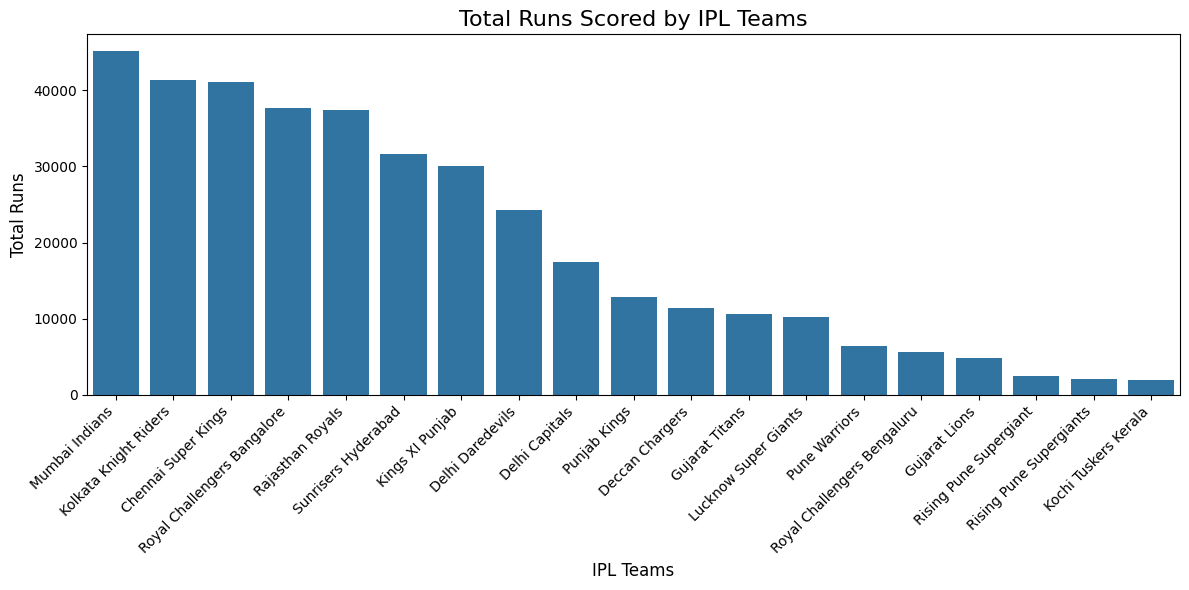

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=team_runs.index,
    y=team_runs['total_runs']
)

plt.title('Total Runs Scored by IPL Teams', fontsize=16)
plt.xlabel('IPL Teams', fontsize=12)
plt.ylabel('Total Runs', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [35]:
deliveries['date'] = pd.to_datetime(deliveries['date'])

In [50]:
deliveries['date_year'] = deliveries['date'].dt.year
total_runs = deliveries.groupby('date_year')[['batsman_runs' , 'extras']].sum()
total_runs

,batsman_runs,extras
date_year,,
2008,16809,1128
2009,15376,977
2010,17754,1129
2011,19928,1226
2012,21323,1130
2013,21487,1115
2014,17943,988
2015,17427,926
2016,17962,900


In [51]:
total_runs['yearly_runs'] = total_runs['batsman_runs'] + total_runs['extras']
total_runs

,batsman_runs,extras,yearly_runs
date_year,,,
2008,16809,1128,17937
2009,15376,977,16353
2010,17754,1129,18883
2011,19928,1226,21154
2012,21323,1130,22453
2013,21487,1115,22602
2014,17943,988,18931
2015,17427,926,18353
2016,17962,900,18862


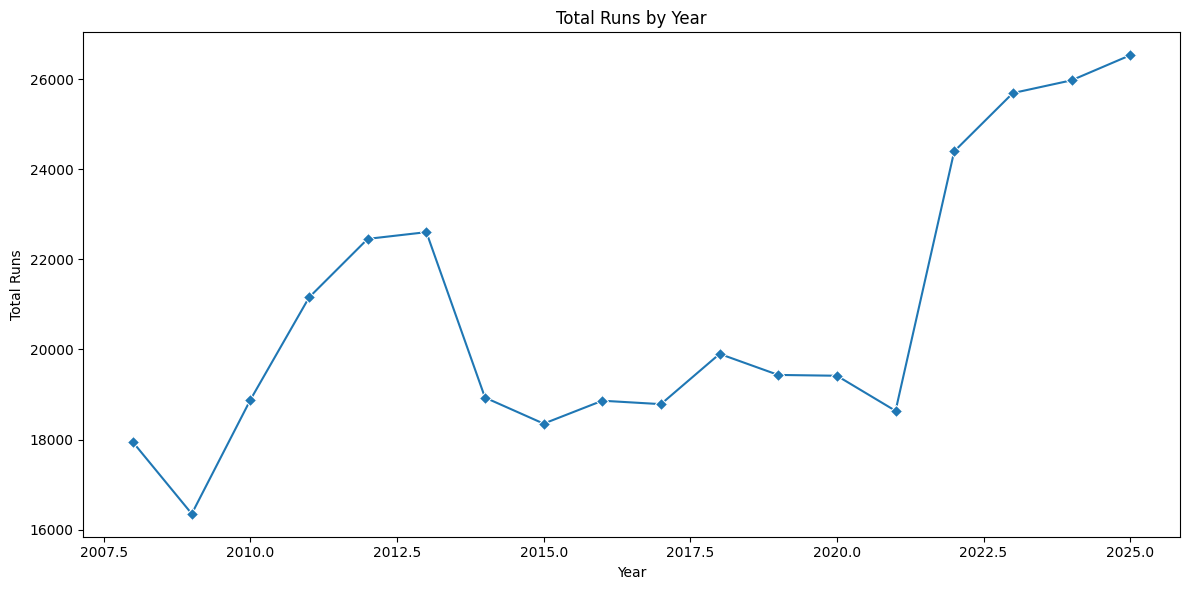

In [62]:
plt.figure(figsize=(12, 6))
plt.title('Total Runs by Year')
plt.xlabel('Year')
plt.ylabel('Total Runs')

sns.lineplot(
    x = total_runs.index,
    y = total_runs['yearly_runs'],
    marker = 'D'
)

plt.tight_layout()
plt.show()

,batsman_runs,extras,yearly_runs
date_year,,,
2008,16809,1128,17937
2009,15376,977,16353
2010,17754,1129,18883
2011,19928,1226,21154
2012,21323,1130,22453


In [67]:
top10batsman = deliveries.groupby('batsman')['batsman_runs'].sum().sort_values(ascending = False).head(10)
top10batsman

,batsman_runs
batsman,
V Kohli,8671
RG Sharma,7048
S Dhawan,6769
DA Warner,6567
SK Raina,5536
MS Dhoni,5439
KL Rahul,5235
AB de Villiers,5181
AM Rahane,5032


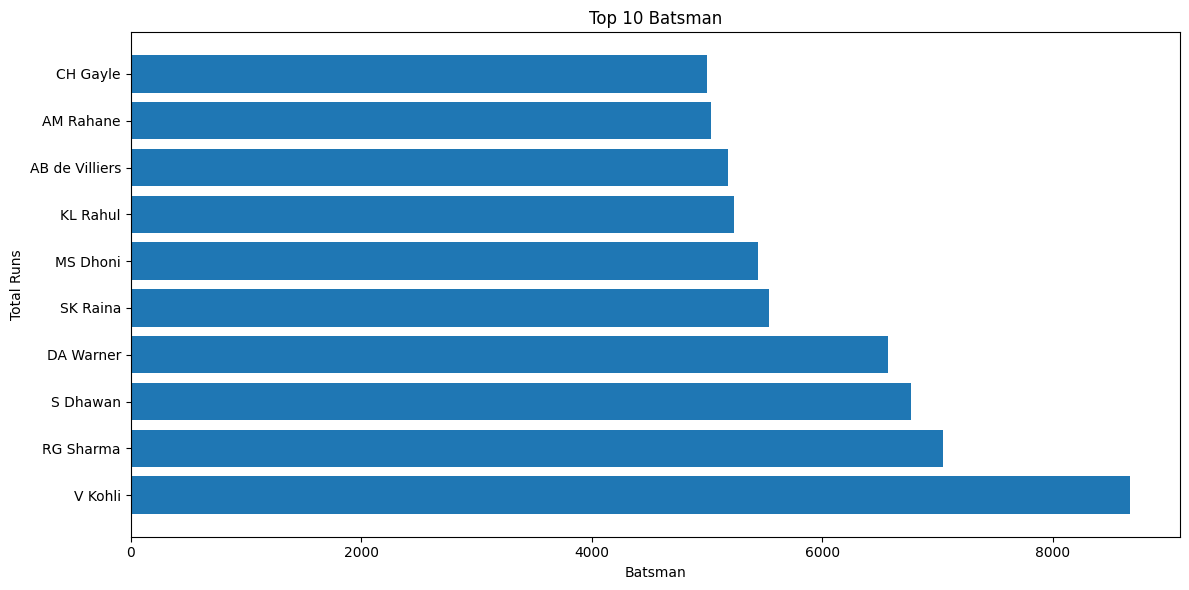

In [79]:
plt.figure(figsize=(12,6))
plt.title('Top 10 Batsman')
plt.xlabel('Batsman')
plt.ylabel('Total Runs')

plt.barh(top10batsman.index, top10batsman.values)

plt.tight_layout()
plt.show()

In [84]:
top10bowlers = deliveries.groupby('bowler')['player_dismissed'].count().sort_values(ascending = False).head(10)
top10bowlers

,player_dismissed
bowler,
YS Chahal,229
B Kumar,213
SP Narine,212
DJ Bravo,207
R Ashwin,205
JJ Bumrah,203
PP Chawla,201
SL Malinga,188
A Mishra,183


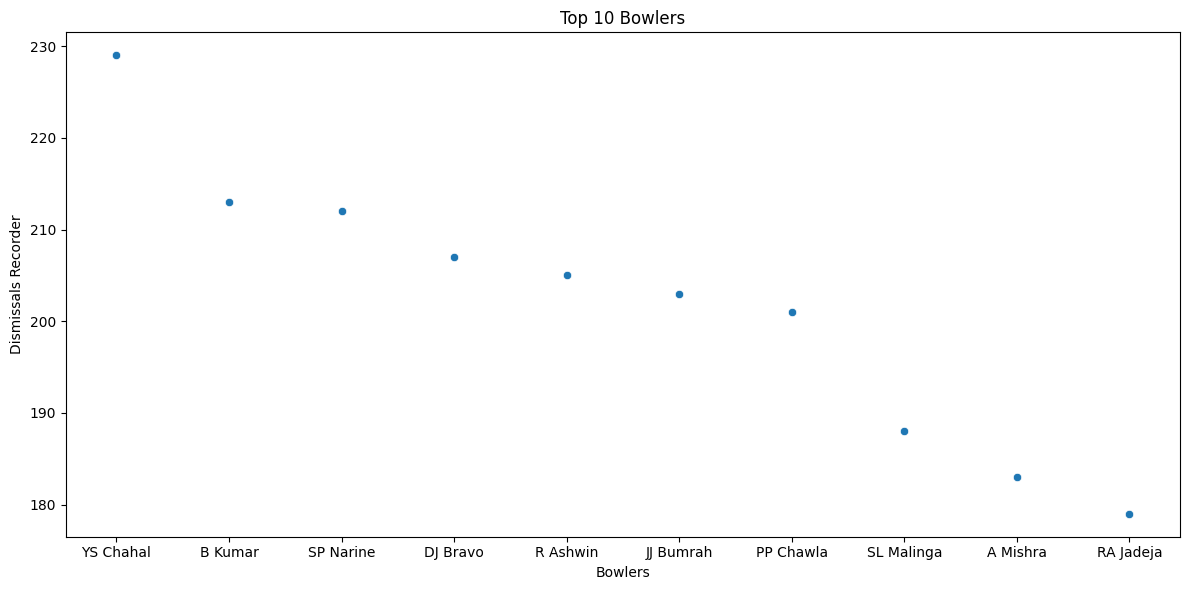

In [89]:
plt.figure(figsize = (12 , 6))
plt.title('Top 10 Bowlers')
plt.xlabel('Bowlers')
plt.ylabel('Dismissals Recorder')

sns.scatterplot(
    x = top10bowlers.index,
    y = top10bowlers.values
)

plt.tight_layout()
plt.show()

In [104]:
toss_decision = matches['toss_decision'].value_counts()
toss_decision

,count
toss_decision,
field,764
bat,405


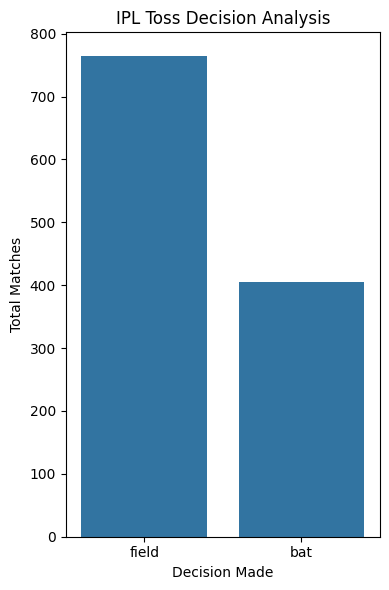

In [112]:
plt.figure(figsize = (4 , 6))
plt.title('IPL Toss Decision Analysis')
plt.xlabel('Decision Made')
plt.ylabel('Total Matches')

sns.countplot(
    data = matches,
    x = 'toss_decision'
)

plt.tight_layout()
plt.show()

In [118]:
toss_match_result = (matches['toss_winner'] == matches['winner']).value_counts()
toss_match_result

,count
True,591
False,578


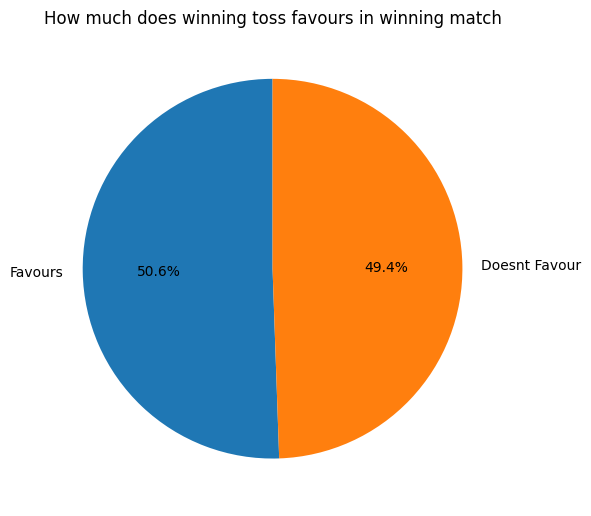

In [119]:
plt.figure(figsize = (6 , 6))
plt.title('How much does winning toss favours in winning match')

plt.pie(
    toss_match_result.values,
    labels = ['Favours' , 'Doesnt Favour'],
    autopct = '%1.1f%%',
    startangle = 90
)

plt.tight_layout()
plt.show()

# **# Key Insights and Conclusions**

## 1. Team-wise Scoring
Mumbai Indians recorded the highest cumulative total at 45,088 runs, followed by Kolkata Knight Riders and Chennai Super Kings.

**Insight:** These are cumulative totals, so differences in matches played and historical franchise names affect the comparison.

## 2. Year-wise Scoring
The highest calendar-year total in the analysis was 26,527 runs in 2025. Total runs increased noticeably from 2021 to 2022.

**Insight:** Annual totals can vary with the number of matches played, so they do not independently establish that scoring per match has increased.

## 3. Top Run-scorers
V Kohli ranked first with 8,671 runs, followed by RG Sharma with 7,048 runs and S Dhawan with 6,769 runs.

**Insight:** Cumulative runs show overall scoring volume; batting average and strike rate would provide additional performance context.

## 4. Bowling Dismissals
YS Chahal had the highest recorded dismissal count in the current analysis, with 229, followed by B Kumar with 213.

**Insight:** The current calculation includes dismissals such as run-outs that are not credited to the bowler. It should not be treated as an official bowler-wickets ranking without filtering dismissal types.

## 5. Toss Decisions
Teams chose to field in 764 matches (65.4%) and chose to bat in 405 matches (34.6%).

**Insight:** Fielding first was the more common toss decision in this dataset. This does not establish which decision is more successful.

## 6. Toss Winner and Match Winner
Among 1,146 matches with recorded winners, the toss winner also won 591 matches, approximately 51.6%.

**Insight:** The toss winner won slightly more than half of these matches. This descriptive result does not prove that winning the toss causes a team to win the match.

## 7. Data Quality
The match dataset contained 23 missing values in the winner column, and the delivery dataset contained 3 duplicate rows. The delivery table also showed unexpected additional columns that require investigation.

**Recommendation:** Before publishing final results, investigate duplicate deliveries, remove unintended columns while preserving intended fields, and exclude matches with missing winners from toss-outcome calculations.

## Conclusion
This exploratory analysis highlights IPL scoring patterns, leading run-scorers, recorded dismissal counts, toss decisions, and match outcomes. It also demonstrates why data quality, fair comparisons, and careful interpretation are essential when analyzing sports data.